In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests
from arch import arch_model

# Load data
df = pd.read_csv('/Users/macbook/Downloads/indonesia-financial-timeseries/data/clean_data.csv', parse_dates=['Date'], index_col='Date')

# Hitung return harian IHSG (dalam persen agar skalanya bagus untuk GARCH)
df['IHSG_ret'] = df['IHSG'].pct_change() * 100
df = df.dropna(subset=['IHSG_ret'])

print("Data siap dianalisis.")

Data siap dianalisis.


In [4]:
print("=== UJI KAUSALITAS GRANGER ===")
print("Hipotesis Nol (H0): Variabel X TIDAK menyebabkan pergerakan IHSG.")
print("Jika p-value < 0.05, maka X secara statistik MEMILIKI pengaruh terhadap IHSG.\n")

# Siapkan data
df['OIL_ret'] = df['OIL'].pct_change()
df['USDIDR_ret'] = df['USDIDR'].pct_change()
df_gc = df[['IHSG_ret', 'OIL_ret', 'USDIDR_ret']].dropna()

# Uji apakah Minyak (OIL) mempengaruhi IHSG
print("1. Apakah Minyak (OIL) mempengaruhi IHSG?")
# Menghapus parameter verbose=False
gc_res_oil = grangercausalitytests(df_gc[['IHSG_ret', 'OIL_ret']], maxlag=[5])
p_value_oil = gc_res_oil[5][0]['ssr_ftest'][1]
print(f"   P-value: {p_value_oil:.4f}")
print("   Kesimpulan:", "Ada pengaruh signifikan." if p_value_oil < 0.05 else "Tidak ada pengaruh signifikan.\n")

# Uji apakah USDIDR mempengaruhi IHSG
print("2. Apakah Nilai Tukar (USDIDR) mempengaruhi IHSG?")
gc_res_idr = grangercausalitytests(df_gc[['IHSG_ret', 'USDIDR_ret']], maxlag=[5])
p_value_idr = gc_res_idr[5][0]['ssr_ftest'][1]
print(f"   P-value: {p_value_idr:.4f}")
print("   Kesimpulan:", "Ada pengaruh signifikan." if p_value_idr < 0.05 else "Tidak ada pengaruh signifikan.")

=== UJI KAUSALITAS GRANGER ===
Hipotesis Nol (H0): Variabel X TIDAK menyebabkan pergerakan IHSG.
Jika p-value < 0.05, maka X secara statistik MEMILIKI pengaruh terhadap IHSG.

1. Apakah Minyak (OIL) mempengaruhi IHSG?
   P-value: 0.0000
   Kesimpulan: Ada pengaruh signifikan.
2. Apakah Nilai Tukar (USDIDR) mempengaruhi IHSG?
   P-value: 0.1681
   Kesimpulan: Tidak ada pengaruh signifikan.


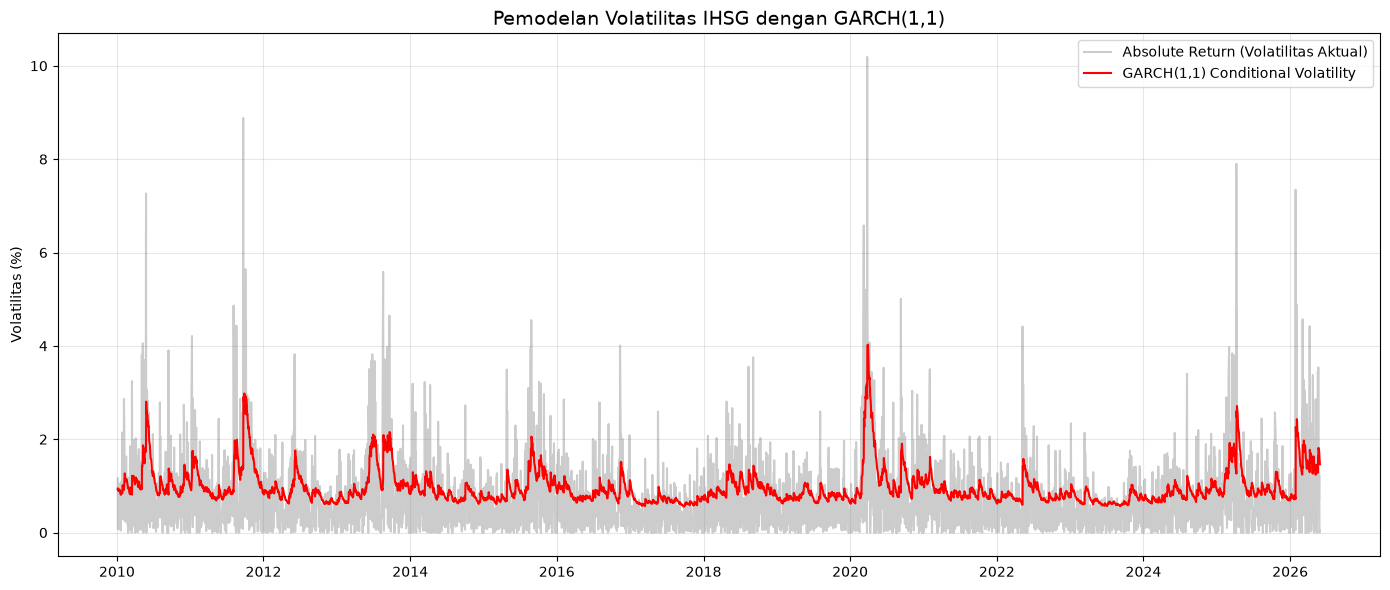

                     Constant Mean - GARCH Model Results                      
Dep. Variable:               IHSG_ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -5685.48
Distribution:                  Normal   AIC:                           11379.0
Method:            Maximum Likelihood   BIC:                           11404.4
                                        No. Observations:                 4275
Date:                Mon, Nov 16 2026   Df Residuals:                     4274
Time:                        07:00:38   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0394  1.288e-02      3.062  2.201e-03 [1.

In [5]:
# Model GARCH(1,1) untuk IHSG
# Model ini memprediksi variance (volatilitas) dari return IHSG
model_garch = arch_model(df['IHSG_ret'], vol='Garch', p=1, q=1)
res_garch = model_garch.fit(disp='off')

# Simpan hasil prediksi volatilitas (conditional volatility)
df['IHSG_vol_pred'] = res_garch.conditional_volatility

# Visualisasi Volatilitas Historis vs Prediksi GARCH
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['IHSG_ret'].abs(), color='gray', alpha=0.4, label='Absolute Return (Volatilitas Aktual)')
plt.plot(df.index, df['IHSG_vol_pred'], color='red', linewidth=1.5, label='GARCH(1,1) Conditional Volatility')
plt.title('Pemodelan Volatilitas IHSG dengan GARCH(1,1)', fontsize=14)
plt.ylabel('Volatilitas (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(res_garch.summary())